(164, 6) (164, 7)
['Date', 'actual', 'Persistence', 'GARCH', 'HAR+IV (lin)', 'HAR+IV (log)', 'TimeMixer ens10']


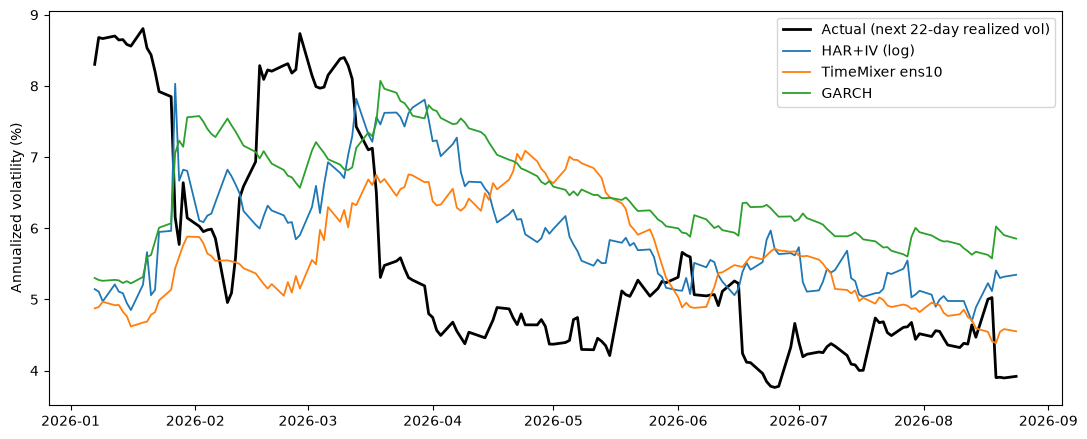

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

val = pd.read_csv("results/val_predictions.csv", parse_dates=["Date"])
test = pd.read_csv("results/test_predictions.csv", parse_dates=["Date"])
print(val.shape, test.shape)
print(test.columns.tolist())

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(test["Date"], test["actual"], color="black", lw=2, label="Actual (next 22-day realized vol)")
for c in ["HAR+IV (log)", "TimeMixer ens10", "GARCH"]:
    ax.plot(test["Date"], test[c], lw=1.3, label=c)
ax.set_ylabel("Annualized volatility (%)")
ax.legend()
plt.tight_layout()
plt.savefig("results/test_forecasts.png", dpi=200)
plt.show()

In [2]:
mdf = pd.read_csv("data/eurusd_model_ready.csv", parse_dates=["Date"])
t = mdf[mdf["Date"] >= "2026-01-01"].copy()
t["abs_ret_pct"] = t["log_return"].abs() * 100
print(t.nlargest(6, "abs_ret_pct")[["Date", "abs_ret_pct"]].round({"abs_ret_pct": 2}))
print("median abs daily return (%):", round(t["abs_ret_pct"].median(), 2))

           Date  abs_ret_pct
1090 2026-01-27         1.35
1127 2026-03-19         1.19
1114 2026-03-02         1.06
1093 2026-01-30         1.01
1191 2026-06-17         0.93
1236 2026-08-19         0.87
median abs daily return (%): 0.21


In [3]:
import numpy as np, pandas as pd

val = pd.read_csv("results/val_predictions.csv", parse_dates=["Date"])
test = pd.read_csv("results/test_predictions.csv", parse_dates=["Date"])

def qlike(y, p):
    r = (y ** 2) / (p ** 2)
    return np.mean(r - np.log(r) - 1)

def table(df):
    y = df["actual"].values
    rows = []
    for c in [c for c in df.columns if c not in ("Date", "actual")]:
        p = df[c].values
        rows.append({"model": c,
                     "RMSE": np.sqrt(np.mean((y - p) ** 2)),
                     "MAE": np.mean(np.abs(y - p)),
                     "bias": np.mean(p - y),
                     "QLIKE": qlike(y, p)})
    return pd.DataFrame(rows).set_index("model").round(3)

tv, tt = table(val), table(test)
print("VALIDATION\n", tv, "\n\nTEST\n", tt)

pd.concat({"validation": tv, "test": tt}, axis=1).to_csv("results/results_table.csv")

VALIDATION
                   RMSE    MAE   bias  QLIKE
model                                      
GARCH            2.344  2.211  1.685  0.220
HAR+IV (lin)     1.770  1.549  1.031  0.152
HAR+IV (log)     1.679  1.461  0.879  0.140
TimeMixer ens10  1.589  1.417  0.801  0.123 

TEST
                   RMSE    MAE   bias  QLIKE
model                                      
Persistence      2.169  1.580  0.090  0.425
GARCH            1.919  1.751  0.946  0.192
HAR+IV (lin)     1.645  1.408  0.517  0.148
HAR+IV (log)     1.634  1.351  0.363  0.153
TimeMixer ens10  1.819  1.471  0.117  0.207


In [4]:
import sys, os, copy, torch, torch.nn as nn
import numpy as np, pandas as pd
from types import SimpleNamespace
sys.path.insert(0, "TimeMixer")
from models.TimeMixer import Model

d = np.load("data/windows_N64.npz", allow_pickle=True)
Xtr, ytr, Xva, yva, Xte, yte = [d[k] for k in ["Xtr", "ytr", "Xva", "yva", "Xte", "yte"]]
y_mu, y_sd = float(d["y_mu"]), float(d["y_sd"])

cfg = SimpleNamespace(
    task_name="long_term_forecast", seq_len=64, label_len=0, pred_len=1,
    enc_in=7, c_out=7, d_model=8, d_ff=16, e_layers=2, dropout=0.2,
    down_sampling_layers=3, down_sampling_window=2, down_sampling_method="avg",
    channel_independence=0, use_norm=0, decomp_method="moving_avg",
    moving_avg=5, top_k=5, embed="timeF", freq="d",
    use_future_temporal_feature=0, num_class=0,
)

class Net(nn.Module):
    def __init__(self, core):
        super().__init__()
        self.core = core
        self.readout = nn.Linear(7, 1)
    def forward(self, x):
        z = self.core(x, None, None, None)
        return self.readout(z[:, 0, :]).squeeze(-1)

to_t = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr_t, ytr_t, Xva_t, yva_t, Xte_t = map(to_t, [Xtr, ytr, Xva, yva, Xte])

def train_seed(s):
    torch.manual_seed(s); np.random.seed(s)
    net = Net(Model(cfg))
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.MSELoss()
    best, best_state, bad = float("inf"), None, 0
    for epoch in range(100):
        net.train()
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(perm), 32):
            idx = perm[i:i + 32]
            opt.zero_grad()
            loss_fn(net(Xtr_t[idx]), ytr_t[idx]).backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            v = loss_fn(net(Xva_t), yva_t).item()
        if v < best - 1e-5:
            best, bad = v, 0
            best_state = {k: x.clone() for k, x in net.state_dict().items()}
        else:
            bad += 1
            if bad >= 10:
                break
    net.load_state_dict(best_state)
    return net.eval()

os.makedirs("results/models", exist_ok=True)
nets = []
for s in range(10):
    n = train_seed(s)
    torch.save(n.state_dict(), f"results/models/tm_seed{s}.pt")
    nets.append(n)

def ens_predict(X_t):
    with torch.no_grad():
        return np.mean([np.exp(n(X_t).numpy() * y_sd + y_mu) for n in nets], axis=0)

val = pd.read_csv("results/val_predictions.csv", parse_dates=["Date"])
test = pd.read_csv("results/test_predictions.csv", parse_dates=["Date"])
yv = val["actual"].values; yt = test["actual"].values
rm = lambda y, p: round(float(np.sqrt(np.mean((y - p) ** 2))), 3)
print("val ensemble RMSE (expect 1.589):", rm(yv, ens_predict(Xva_t)))
print("test ensemble RMSE (expect 1.819):", rm(yt, ens_predict(Xte_t)))
print("saved models:", len(os.listdir("results/models")))

val ensemble RMSE (expect 1.589): 1.589
test ensemble RMSE (expect 1.819): 1.819
saved models: 10


additivity max error: 1.0152143659070134e-07
v(all on) matches model output: 3.5762786865234375e-07
         feature  mean |contribution| (%)  share (%)  mean signed (%)
     IMPL_VOL_1M                    16.31       38.7           -16.31
          park_w                    12.13       28.8           -12.13
          park_d                     3.62        8.6             3.57
realized_vol_22d                     3.44        8.2            -1.27
         VOL_90D                     2.65        6.3            -0.30
         VOL_10D                     2.06        4.9            -0.37
          park_m                     1.92        4.6            -1.58


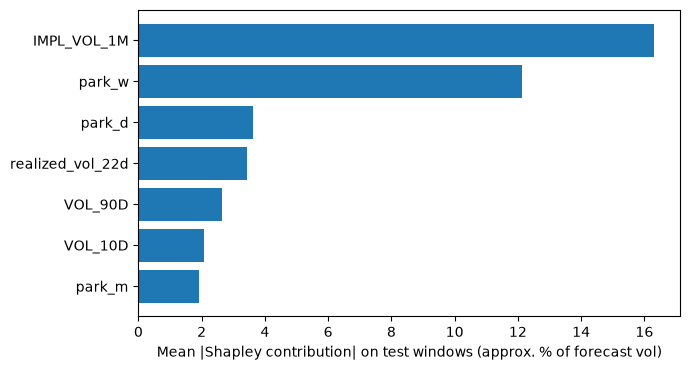

In [10]:
import itertools
from math import factorial
import matplotlib.pyplot as plt

F = 7
names = ["realized_vol_22d", "park_d", "park_w", "park_m", "IMPL_VOL_1M", "VOL_10D", "VOL_90D"]

rng = np.random.default_rng(0)
K = 10
bg = Xtr_t[rng.choice(len(Xtr_t), K, replace=False)]            # (K, 64, 7)

masks = np.array(list(itertools.product([0, 1], repeat=F)), dtype=np.float32)   # (128, 7)
masks_t = torch.tensor(masks)[:, None, None, :]
size = masks.sum(1).astype(int)
idx = {tuple(m.astype(int)): i for i, m in enumerate(masks)}

def f_ens(X):
    with torch.no_grad():
        return torch.stack([n(X) for n in nets]).mean(0)

def coalition_values(x):                      # x: (64, 7)
    mixed = masks_t * x[None, None] + (1 - masks_t) * bg[None]   # (128, K, 64, 7)
    return f_ens(mixed.reshape(-1, 64, F)).reshape(128, K).mean(1).numpy()

def shapley(v):
    phi = np.zeros(F)
    for j in range(F):
        for i, m in enumerate(masks):
            if m[j] == 0:
                s = size[i]
                w = factorial(s) * factorial(F - s - 1) / factorial(F)
                m2 = m.copy(); m2[j] = 1
                phi[j] += w * (v[idx[tuple(m2.astype(int))]] - v[i])
    return phi

phis, vals = [], []
for i in range(len(Xte_t)):
    v = coalition_values(Xte_t[i])
    vals.append(v)
    phis.append(shapley(v))
phis, vals = np.array(phis), np.array(vals)

# additivity check: contributions must sum to (prediction - baseline)
pred_full = f_ens(Xte_t).numpy()
print("additivity max error:", float(np.abs(phis.sum(1) - (vals[:, -1] - vals[:, 0])).max()))
print("v(all on) matches model output:", float(np.abs(vals[:, -1] - pred_full).max()))

imp = np.abs(phis).mean(0) * y_sd * 100
res_df = pd.DataFrame({"feature": names,
                       "mean |contribution| (%)": imp.round(2),
                       "share (%)": (100 * imp / imp.sum()).round(1),
                       "mean signed (%)": (phis.mean(0) * y_sd * 100).round(2)}
                      ).sort_values("share (%)", ascending=False)
print(res_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.8))
r = res_df.iloc[::-1]
ax.barh(r["feature"], r["mean |contribution| (%)"])
ax.set_xlabel("Mean |Shapley contribution| on test windows (approx. % of forecast vol)")
plt.tight_layout(); plt.savefig("results/shap_importance.png", dpi=200); plt.show()
res_df.to_csv("results/shap_importance.csv", index=False)

In [11]:
val = pd.read_csv("results/val_predictions.csv", parse_dates=["Date"])
yv = val["actual"].values

def perm_rmse(X_t, y, j, reps=5):
    out = []
    for r in range(reps):
        g = torch.Generator().manual_seed(r)
        p = torch.randperm(len(X_t), generator=g)
        X2 = X_t.clone()
        X2[:, :, j] = X_t[p][:, :, j]
        out.append(np.sqrt(np.mean((y - ens_predict(X2)) ** 2)))
    return float(np.mean(out))

base = float(np.sqrt(np.mean((yv - ens_predict(Xva_t)) ** 2)))
print("baseline val RMSE:", round(base, 3))
for j, n in enumerate(names):
    print(f"{n:18s} RMSE when shuffled: {perm_rmse(Xva_t, yv, j):.3f}")

baseline val RMSE: 1.589
realized_vol_22d   RMSE when shuffled: 1.735
park_d             RMSE when shuffled: 1.633
park_w             RMSE when shuffled: 1.849
park_m             RMSE when shuffled: 1.627
IMPL_VOL_1M        RMSE when shuffled: 1.876
VOL_10D            RMSE when shuffled: 1.728
VOL_90D            RMSE when shuffled: 1.590


In [13]:
test = pd.read_csv("results/test_predictions.csv", parse_dates=["Date"])
yt = test["actual"].values
base_t = float(np.sqrt(np.mean((yt - ens_predict(Xte_t)) ** 2)))
print("baseline test RMSE:", round(base_t, 3))
for j, n in enumerate(names):
    print(f"{n:18s} RMSE when shuffled: {perm_rmse(Xte_t, yt, j):.3f}")

baseline test RMSE: 1.819
realized_vol_22d   RMSE when shuffled: 1.889
park_d             RMSE when shuffled: 1.840
park_w             RMSE when shuffled: 1.728
park_m             RMSE when shuffled: 1.790
IMPL_VOL_1M        RMSE when shuffled: 1.747
VOL_10D            RMSE when shuffled: 1.816
VOL_90D            RMSE when shuffled: 1.727


In [14]:
for name, df in [("VALIDATION", val), ("TEST", test)]:
    print(name)
    y = df["actual"].values
    for c in [c for c in df.columns if c not in ("Date", "actual")]:
        p = df[c].values
        slope = np.polyfit(p, y, 1)[0]
        print(f"  {c:16s} corr {np.corrcoef(p, y)[0, 1]:6.3f} | slope {slope:6.3f}")

VALIDATION
  GARCH            corr  0.614 | slope  0.935
  HAR+IV (lin)     corr  0.750 | slope  1.425
  HAR+IV (log)     corr  0.750 | slope  1.387
  TimeMixer ens10  corr  0.766 | slope  1.299
TEST
  Persistence      corr  0.084 | slope  0.077
  GARCH            corr  0.022 | slope  0.047
  HAR+IV (lin)     corr  0.215 | slope  0.417
  HAR+IV (log)     corr  0.175 | slope  0.338
  TimeMixer ens10  corr -0.184 | slope -0.381


In [15]:
import statsmodels.api as sm
from arch import arch_model

mdf = pd.read_csv("data/eurusd_model_ready.csv", parse_dates=["Date"])
feat = ["realized_vol_22d", "park_d", "park_w", "park_m", "IMPL_VOL_1M", "VOL_10D", "VOL_90D"]
har_iv = ["park_d", "park_w", "park_m", "IMPL_VOL_1M"]
logF = np.log(mdf[feat]).values
y_all = mdf["target_22d"].values
ly = np.log(y_all)
n, N, GAP, VAL, BLOCK = len(mdf), 64, 22, 100, 155
starts = [620, 775, 930, 1085]
r_pct = mdf.set_index("Date")["log_return"] * 100

def run_fold(a, b, seeds=5):
    tr_end = a - GAP - VAL - GAP
    tr = np.arange(0, tr_end)
    va = np.arange(tr_end + GAP, a - GAP)
    te = np.arange(a, b)

    mu, sd = logF[tr].mean(0), logF[tr].std(0, ddof=1)
    Xs = (logF - mu) / sd
    ymu, ysd = ly[tr].mean(), ly[tr].std(ddof=1)
    ys = (ly - ymu) / ysd

    def win(idx):
        return torch.tensor(np.stack([Xs[i - N + 1:i + 1] for i in idx]), dtype=torch.float32)

    tr_w = tr[tr >= N - 1]
    Xt, yt_ = win(tr_w), torch.tensor(ys[tr_w], dtype=torch.float32)
    Xv, yv_ = win(va), torch.tensor(ys[va], dtype=torch.float32)
    Xe = win(te)

    out = pd.DataFrame({"Date": mdf["Date"].values[te], "actual": y_all[te], "fold": a})
    out["Train-mean"] = y_all[tr].mean()
    out["Persistence"] = mdf["realized_vol_22d"].values[te]

    m_lin = sm.OLS(y_all[tr], sm.add_constant(mdf[har_iv].iloc[tr])).fit()
    out["HAR+IV (lin)"] = m_lin.predict(sm.add_constant(mdf[har_iv].iloc[te], has_constant="add")).values

    lc = np.log(mdf[har_iv])
    m_log = sm.OLS(ly[tr], sm.add_constant(lc.iloc[tr])).fit()
    out["HAR+IV (log)"] = np.exp(m_log.predict(sm.add_constant(lc.iloc[te], has_constant="add"))).values

    am = arch_model(r_pct, mean="Constant", vol="GARCH", p=1, q=1, dist="normal")
    res_g = am.fit(last_obs=mdf["Date"].iloc[a - GAP - 1], disp="off")
    fc = res_g.forecast(horizon=22, start=mdf["Date"].iloc[a], reindex=False)
    g = np.sqrt(fc.variance.mean(axis=1) * 252)
    out["GARCH"] = g.reindex(pd.DatetimeIndex(mdf["Date"].iloc[te])).values

    preds = []
    for s in range(seeds):
        torch.manual_seed(s); np.random.seed(s)
        net = Net(Model(cfg))
        opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
        lf = nn.MSELoss()
        best, best_state, bad = float("inf"), None, 0
        for ep in range(100):
            net.train()
            perm = torch.randperm(len(Xt))
            for i in range(0, len(perm), 32):
                ix = perm[i:i + 32]
                opt.zero_grad()
                lf(net(Xt[ix]), yt_[ix]).backward()
                opt.step()
            net.eval()
            with torch.no_grad():
                v = lf(net(Xv), yv_).item()
            if v < best - 1e-5:
                best, bad = v, 0
                best_state = {k: x.clone() for k, x in net.state_dict().items()}
            else:
                bad += 1
                if bad >= 10:
                    break
        net.load_state_dict(best_state)
        net.eval()
        with torch.no_grad():
            preds.append(np.exp(net(Xe).numpy() * ysd + ymu))
    out["TimeMixer ens5"] = np.mean(preds, axis=0)
    for s, p in enumerate(preds):
        out[f"tm_seed{s}"] = p
    return out

folds = []
for a in starts:
    b = min(a + BLOCK, n)
    print("fold:", mdf["Date"].iloc[a].date(), "->", mdf["Date"].iloc[b - 1].date(), flush=True)
    folds.append(run_fold(a, b))

roll = pd.concat(folds, ignore_index=True)
roll.to_csv("results/rolling_predictions.csv", index=False)
print(roll.shape, "| NaNs:", int(roll.isnull().sum().sum()))

fold: 2024-04-09 -> 2024-11-11
fold: 2024-11-12 -> 2025-06-16
fold: 2025-06-17 -> 2026-01-19
fold: 2026-01-20 -> 2026-08-24
(620, 14) | NaNs: 0


In [16]:
from scipy import stats

meta = ["Date", "actual", "fold"]
models = [c for c in roll.columns if c not in meta and not c.startswith("tm_seed")]
y = roll["actual"].values

def qlike(y, p):
    r = (y ** 2) / (p ** 2)
    return np.mean(r - np.log(r) - 1)

def dm_hac(y, p1, p2, lags=21):
    d = (y - p1) ** 2 - (y - p2) ** 2          # positive => model 2 better
    T = len(d); e = d - d.mean()
    var = (e @ e) / T
    for k in range(1, lags + 1):
        var += 2 * (1 - k / (lags + 1)) * (e[k:] @ e[:-k]) / T
    s = d.mean() / np.sqrt(var / T)
    return s, 2 * (1 - stats.norm.cdf(abs(s)))

tab = pd.DataFrame({m: {"RMSE": np.sqrt(np.mean((y - roll[m]) ** 2)),
                        "MAE": np.mean(np.abs(y - roll[m])),
                        "bias": np.mean(roll[m] - y),
                        "QLIKE": qlike(y, roll[m].values),
                        "corr": np.corrcoef(roll[m], y)[0, 1]} for m in models}).T.round(3)
print("POOLED (all 4 test blocks)\n", tab, "\n")

byfold = pd.DataFrame({f: {m: np.sqrt(np.mean((g["actual"] - g[m]) ** 2)) for m in models}
                       for f, g in roll.groupby("fold")}).T.round(3)
print("RMSE BY FOLD (index = fold start row)\n", byfold, "\n")

single = [np.sqrt(np.mean((y - roll[f"tm_seed{s}"]) ** 2)) for s in range(5)]
print("TimeMixer single-seed pooled RMSE: mean", round(np.mean(single), 3), "std", round(np.std(single), 3), "\n")

for m in ["Train-mean", "GARCH", "HAR+IV (lin)", "HAR+IV (log)"]:
    s, p = dm_hac(y, roll[m].values, roll["TimeMixer ens5"].values)
    print(f"DM {m:14s} vs TimeMixer: stat {s:5.2f}, p {p:.3f}")

tab.to_csv("results/rolling_table.csv")

POOLED (all 4 test blocks)
                  RMSE    MAE   bias  QLIKE   corr
Train-mean      2.728  2.354  1.466  0.275  0.006
Persistence     2.332  1.860  0.063  0.329  0.467
HAR+IV (lin)    1.855  1.487  0.453  0.153  0.624
HAR+IV (log)    1.828  1.440  0.305  0.152  0.620
GARCH           2.145  1.845  0.713  0.196  0.468
TimeMixer ens5  1.967  1.532 -0.047  0.193  0.505 

RMSE BY FOLD (index = fold start row)
       Train-mean  Persistence  HAR+IV (lin)  HAR+IV (log)  GARCH  \
620        3.180        2.207         1.641         1.597  1.883   
775        2.266        2.620         2.206         2.217  2.406   
930        2.674        2.613         1.982         1.950  2.420   
1085       2.714        1.787         1.509         1.447  1.794   

      TimeMixer ens5  
620            1.721  
775            2.372  
930            2.129  
1085           1.532   

TimeMixer single-seed pooled RMSE: mean 2.032 std 0.057 

DM Train-mean     vs TimeMixer: stat  3.00, p 0.003
DM GARCH     

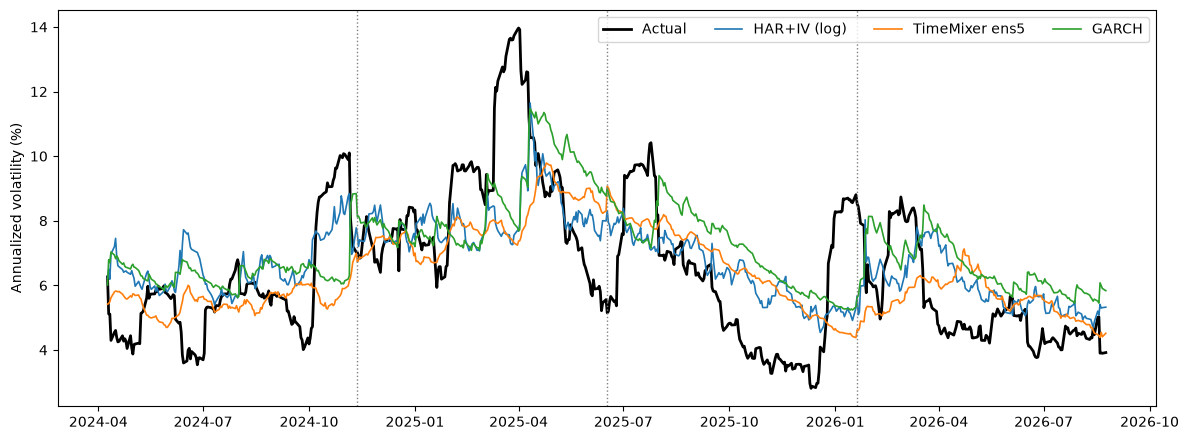

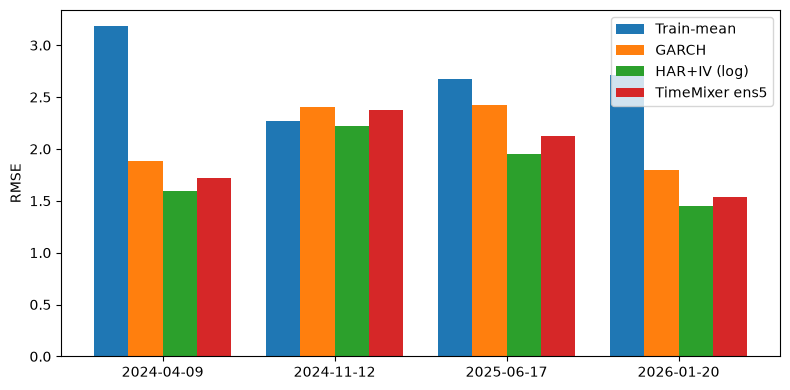

DM GARCH vs HAR+IV (log): stat 2.97, p 0.003
DM Train-mean vs HAR+IV (log): stat 4.38, p 0.000


In [17]:
import matplotlib.pyplot as plt

roll = pd.read_csv("results/rolling_predictions.csv", parse_dates=["Date"])
y = roll["actual"].values

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(roll["Date"], roll["actual"], color="black", lw=2, label="Actual")
for c in ["HAR+IV (log)", "TimeMixer ens5", "GARCH"]:
    ax.plot(roll["Date"], roll[c], lw=1.2, label=c)
for d0 in roll.groupby("fold")["Date"].min().iloc[1:]:
    ax.axvline(d0, color="grey", ls=":", lw=1)
ax.set_ylabel("Annualized volatility (%)"); ax.legend(ncol=4)
plt.tight_layout(); plt.savefig("results/rolling_forecasts.png", dpi=200); plt.show()

models = ["Train-mean", "GARCH", "HAR+IV (log)", "TimeMixer ens5"]
labels, vals = [], {m: [] for m in models}
for f, g in roll.groupby("fold"):
    labels.append(str(g["Date"].min().date()))
    for m in models:
        vals[m].append(np.sqrt(np.mean((g["actual"] - g[m]) ** 2)))
x = np.arange(len(labels)); w = 0.2
fig, ax = plt.subplots(figsize=(8, 4))
for i, m in enumerate(models):
    ax.bar(x + (i - 1.5) * w, vals[m], w, label=m)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("RMSE"); ax.legend()
plt.tight_layout(); plt.savefig("results/rolling_by_fold.png", dpi=200); plt.show()

for a, b in [("GARCH", "HAR+IV (log)"), ("Train-mean", "HAR+IV (log)")]:
    s, p = dm_hac(y, roll[a].values, roll[b].values)
    print(f"DM {a} vs {b}: stat {s:.2f}, p {p:.3f}")

In [18]:
import numpy as np, pandas as pd
from scipy import stats

roll = pd.read_csv("results/rolling_predictions.csv", parse_dates=["Date"])
y = roll["actual"].values

def dm_hln(y, p1, p2, h=22, lags=21):
    d = (y - p1) ** 2 - (y - p2) ** 2          # positive => model 2 better
    T = len(d); e = d - d.mean()
    var = (e @ e) / T
    for k in range(1, lags + 1):
        var += 2 * (1 - k / (lags + 1)) * (e[k:] @ e[:-k]) / T
    stat = d.mean() / np.sqrt(var / T)
    stat *= np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)   # HLN correction
    return stat, 2 * (1 - stats.t.cdf(abs(stat), T - 1))

pairs = [("GARCH", "HAR+IV (log)"), ("Train-mean", "HAR+IV (log)"),
         ("Train-mean", "TimeMixer ens5"), ("GARCH", "TimeMixer ens5"),
         ("HAR+IV (log)", "TimeMixer ens5"), ("HAR+IV (lin)", "TimeMixer ens5")]
for a, b in pairs:
    s, p = dm_hln(y, roll[a].values, roll[b].values)
    print(f"DM-HLN  {a:14s} vs {b:14s}: stat {s:6.2f}, p {p:.3f}")

DM-HLN  GARCH          vs HAR+IV (log)  : stat   2.87, p 0.004
DM-HLN  Train-mean     vs HAR+IV (log)  : stat   4.23, p 0.000
DM-HLN  Train-mean     vs TimeMixer ens5: stat   2.89, p 0.004
DM-HLN  GARCH          vs TimeMixer ens5: stat   1.60, p 0.111
DM-HLN  HAR+IV (log)   vs TimeMixer ens5: stat  -1.11, p 0.268
DM-HLN  HAR+IV (lin)   vs TimeMixer ens5: stat  -0.82, p 0.413
